In [1]:
import pandas as pd
import math
from collections import Counter
from nltk.util import bigrams, trigrams, ngrams

In [2]:
df = pd.read_csv("../dataset/dataset_preprocessed.csv")
text_column = "processed_text"  # gunakan hasil preprocessing

# Hapus nilai kosong
df = df.dropna(subset=[text_column])

print(f"Jumlah dokumen: {len(df)}")

Jumlah dokumen: 69537


In [3]:
all_text = " ".join(df[text_column].astype(str))
tokens = all_text.split()

print(f"Total token: {len(tokens)}")
print(f"Contoh token: {tokens[:20]}")

Total token: 573396
Contoh token: ['kualitas', 'ok', 'layan', 'ok', 'kemas', 'baguspengiriman', 'respon', 'oke', 'moga', 'hasil', 'mantap', 'ok', 'paket', 'sampai', 'tks', 'gan', 'produk', 'bagus', 'seller', 'top']


In [4]:
unigram = Counter(tokens)

print("20 Kata Paling Sering Muncul:")
for word, count in unigram.most_common(20):
    print(f"  {word:<20} : {count}")

20 Kata Paling Sering Muncul:
  barang               : 21274
  sesuai               : 15242
  kirim                : 14339
  cepat                : 13417
  bagus                : 11976
  terima               : 9008
  nya                  : 7794
  yg                   : 7326
  produk               : 6134
  pesan                : 5822
  seller               : 5759
  kasih                : 5397
  packing              : 5200
  aman                 : 5022
  respon               : 4597
  kualitas             : 4490
  beli                 : 4417
  deskripsi            : 3945
  banget               : 3827
  ga                   : 3819


In [5]:
total_tokens = sum(unigram.values())

unigram_probability = {
    word: count / total_tokens
    for word, count in unigram.items()
}

print("\n10 Kata dengan Probabilitas Tertinggi:")
sorted_prob = sorted(
    unigram_probability.items(),
    key=lambda x: x[1],
    reverse=True
)
for word, prob in sorted_prob[:10]:
    print(f"  {word:<20} : {prob:.6f}")


10 Kata dengan Probabilitas Tertinggi:
  barang               : 0.037102
  sesuai               : 0.026582
  kirim                : 0.025007
  cepat                : 0.023399
  bagus                : 0.020886
  terima               : 0.015710
  nya                  : 0.013593
  yg                   : 0.012777
  produk               : 0.010698
  pesan                : 0.010154


In [6]:
bigram_tokens = list(bigrams(tokens))
bigram_frequency = Counter(bigram_tokens)

print("20 Bigram Paling Sering Muncul:")
for bigram, count in bigram_frequency.most_common(20):
    print(f"  {' '.join(bigram):<30} : {count}")

20 Bigram Paling Sering Muncul:
  kirim cepat                    : 5788
  barang sesuai                  : 4472
  terima kasih                   : 4020
  sesuai deskripsi               : 3340
  sesuai pesan                   : 3194
  barang bagus                   : 2644
  barang terima                  : 1954
  cepat barang                   : 1529
  respon cepat                   : 1280
  produk sesuai                  : 1186
  packing aman                   : 1168
  sesuai gambar                  : 1162
  packing rapi                   : 1162
  bagus sesuai                   : 1146
  fast respon                    : 930
  recommended seller             : 892
  cepat packing                  : 854
  cepat kirim                    : 802
  moga awet                      : 789
  produk bagus                   : 758


In [7]:
trigram_tokens = list(trigrams(tokens))
trigram_frequency = Counter(trigram_tokens)

print("20 Trigram Paling Sering Muncul:")
for trigram, count in trigram_frequency.most_common(20):
    print(f"  {' '.join(trigram):<40} : {count}")

20 Trigram Paling Sering Muncul:
  barang sesuai deskripsi                  : 1167
  barang sesuai pesan                      : 1100
  kirim cepat barang                       : 708
  terima kasih barang                      : 658
  cepat barang sesuai                      : 537
  barang bagus sesuai                      : 511
  kirim cepat packing                      : 493
  produk sesuai deskripsi                  : 460
  bagus kirim cepat                        : 408
  cepat terima kasih                       : 350
  cepat kirim cepat                        : 344
  barang sesuai gambar                     : 343
  barang terima sesuai                     : 320
  bagus sesuai deskripsi                   : 292
  sesuai deskripsi kirim                   : 275
  terima sesuai pesan                      : 265
  respon cepat barang                      : 261
  sesuai pesan kirim                       : 260
  aman kirim cepat                         : 246
  respon jual cepat               

In [8]:
def bigram_probability(word1, word2):
    numerator = bigram_frequency[(word1, word2)]
    denominator = unigram[word1]

    if denominator == 0:
        return 0.0

    return numerator / denominator

# Contoh
word1, word2 = "belajar", "nlp"
prob = bigram_probability(word1, word2)
print(f"P({word2} | {word1}) = {prob:.6f}")

P(nlp | belajar) = 0.000000


In [9]:
def sentence_probability(sentence):
    words = sentence.lower().split()
    probability = 1.0

    for i in range(len(words) - 1):
        p = bigram_probability(words[i], words[i + 1])
        probability *= p

    return probability

# Uji
test_sentences = [
    "saya belajar nlp",
    "nlp menarik sekali",
    "model bahasa sederhana",
]

for sentence in test_sentences:
    p = sentence_probability(sentence)
    print(f"P('{sentence}') = {p:.8f}")

P('saya belajar nlp') = 0.00000000
P('nlp menarik sekali') = 0.00000000
P('model bahasa sederhana') = 0.00000000


In [10]:
vocab_size = len(unigram)

def smoothed_bigram_probability(word1, word2):
    numerator = bigram_frequency[(word1, word2)] + 1
    denominator = unigram[word1] + vocab_size
    return numerator / denominator

# Uji dengan kata yang mungkin tidak ada dalam corpus
word1, word2 = "deep", "learning"
prob = smoothed_bigram_probability(word1, word2)
print(f"Smoothed P({word2} | {word1}) = {prob:.8f}")

Smoothed P(learning | deep) = 0.00002921


In [11]:
def predict_next_word(context_word, top_n=5):
    candidates = []

    for (word1, word2), count in bigram_frequency.items():
        if word1 == context_word:
            p = smoothed_bigram_probability(word1, word2)
            candidates.append((word2, p))

    candidates.sort(key=lambda x: x[1], reverse=True)
    return candidates[:top_n]

# Contoh
context = "belajar"
predictions = predict_next_word(context)
print(f"\nPrediksi kata setelah '{context}':")
for word, prob in predictions:
    print(f"  {word:<20} : {prob:.6f}")


Prediksi kata setelah 'belajar':


In [12]:
def perplexity(probability, N):
    if probability == 0 or probability is None:
        return float("inf")
    return probability ** (-1 / N)

# Contoh
sentence = "saya belajar nlp"
words = sentence.split()
prob = sentence_probability(sentence)
N = len(words)

pp = perplexity(prob, N)
print(f"Kalimat : '{sentence}'")
print(f"P(W)    : {prob:.8f}")
print(f"N       : {N}")
print(f"PP(W)   : {pp:.4f}")

Kalimat : 'saya belajar nlp'
P(W)    : 0.00000000
N       : 3
PP(W)   : inf


In [13]:
print("=" * 60)
print("PERBANDINGAN MODEL N-GRAM")
print("=" * 60)
print(f"Ukuran Vocabulary     : {len(unigram):,}")
print(f"Jumlah Token          : {len(tokens):,}")
print(f"Jumlah Unigram unik   : {len(unigram):,}")
print(f"Jumlah Bigram unik    : {len(bigram_frequency):,}")
print(f"Jumlah Trigram unik   : {len(trigram_frequency):,}")
print()

# Cek sparsity
max_bigram = len(unigram) ** 2
max_trigram = len(unigram) ** 3
print(f"Kemungkinan Bigram maks  : {max_bigram:,}")
print(f"Bigram yang ada          : {len(bigram_frequency):,}")
print(f"Bigram coverage          : {len(bigram_frequency)/max_bigram*100:.4f}%")

PERBANDINGAN MODEL N-GRAM
Ukuran Vocabulary     : 34,231
Jumlah Token          : 573,396
Jumlah Unigram unik   : 34,231
Jumlah Bigram unik    : 255,453
Jumlah Trigram unik   : 446,103

Kemungkinan Bigram maks  : 1,171,761,361
Bigram yang ada          : 255,453
Bigram coverage          : 0.0218%


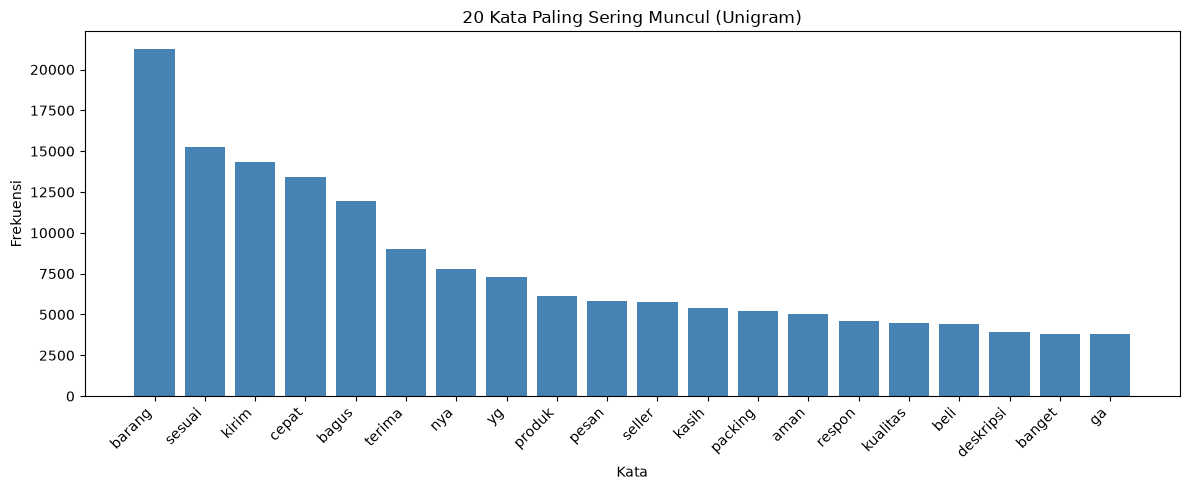

In [14]:
import matplotlib.pyplot as plt

# Top 20 unigram
top_words = unigram.most_common(20)
words_list = [w[0] for w in top_words]
counts_list = [w[1] for w in top_words]

plt.figure(figsize=(12, 5))
plt.bar(words_list, counts_list, color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Kata")
plt.ylabel("Frekuensi")
plt.title("20 Kata Paling Sering Muncul (Unigram)")
plt.tight_layout()
plt.show()